In [6]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Project paths
CURRENT_DIR = Path.cwd().resolve()

if CURRENT_DIR.name == "notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

DATASET_ROOT = PROJECT_ROOT / "dataset"
DATASET_PATH = DATASET_ROOT / "lfw-deepfunneled"
LFW_ROOT = DATASET_PATH / "lfw-deepfunneled"

# Evaluation CSV files
PAIR_FILES = [
    "matchpairsDevTrain.csv",
    "mismatchpairsDevTrain.csv",
    "matchpairsDevTest.csv",
    "mismatchpairsDevTest.csv"
]

print("Project root:", PROJECT_ROOT)
print("Dataset root:", DATASET_ROOT)
print("LFW image root:", LFW_ROOT)

# Verify paths
assert DATASET_ROOT.exists(), "Dataset folder not found!"
assert LFW_ROOT.exists(), "LFW image folder not found!"

for filename in PAIR_FILES:
    file_path = DATASET_ROOT / filename
    print(filename, ":", "Found" if file_path.exists() else "Missing")

Project root: D:\Identity_Monitoring
Dataset root: D:\Identity_Monitoring\dataset
LFW image root: D:\Identity_Monitoring\dataset\lfw-deepfunneled\lfw-deepfunneled
matchpairsDevTrain.csv : Found
mismatchpairsDevTrain.csv : Found
matchpairsDevTest.csv : Found
mismatchpairsDevTest.csv : Found


In [7]:
pair_files = [
    "matchpairsDevTrain.csv",
    "mismatchpairsDevTrain.csv",
    "matchpairsDevTest.csv",
    "mismatchpairsDevTest.csv"
]

pair_data = {}

for filename in pair_files:
    df = pd.read_csv(DATASET_ROOT / filename)
    pair_data[filename] = df

    print(f"\n{'=' * 60}")
    print(f"FILE: {filename}")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    display(df.head(5))


FILE: matchpairsDevTrain.csv
Shape: (1100, 3)
Columns: ['name', 'imagenum1', 'imagenum2']


,name,imagenum1,imagenum2
0,Aaron_Peirsol,1,2
1,Aaron_Peirsol,3,4
2,Aaron_Sorkin,1,2
3,Abdel_Nasser_Assidi,1,2
4,Abdullah,1,3



FILE: mismatchpairsDevTrain.csv
Shape: (1100, 4)
Columns: ['name', 'imagenum1', 'name.1', 'imagenum2']


,name,imagenum1,name.1,imagenum2
0,AJ_Cook,1,Marsha_Thomason,1
1,Aaron_Sorkin,2,Frank_Solich,5
2,Abdel_Nasser_Assidi,2,Hilary_McKay,1
3,Abdoulaye_Wade,4,Linda_Dano,1
4,Abdul_Rahman,1,Magui_Serna,1



FILE: matchpairsDevTest.csv
Shape: (500, 3)
Columns: ['name', 'imagenum1', 'imagenum2']


,name,imagenum1,imagenum2
0,Abdullah_Gul,13,14
1,Abdullah_Gul,13,16
2,Abdullatif_Sener,1,2
3,Adel_Al-Jubeir,1,3
4,Al_Pacino,1,2



FILE: mismatchpairsDevTest.csv
Shape: (500, 4)
Columns: ['name', 'imagenum1', 'name.1', 'imagenum2']


,name,imagenum1,name.1,imagenum2
0,AJ_Lamas,1,Zach_Safrin,1
1,Aaron_Guiel,1,Reese_Witherspoon,3
2,Aaron_Tippin,1,Jose_Luis_Rodriguez_Zapatero,1
3,Abdul_Majeed_Shobokshi,1,Charles_Cope,1
4,Abdullah_Gul,16,Steve_Cox,1


In [8]:
def get_image_path(name, imagenum):
    filename = f"{name}_{int(imagenum):04d}.jpg"
    return LFW_ROOT / name / filename


def prepare_genuine_pairs(df, split):
    result = pd.DataFrame({
        "image1_path": [
            get_image_path(row["name"], row["imagenum1"])
            for _, row in df.iterrows()
        ],
        "image2_path": [
            get_image_path(row["name"], row["imagenum2"])
            for _, row in df.iterrows()
        ],
        "actual_label": 1,
        "pair_type": "Genuine",
        "split": split
    })

    return result


def prepare_impostor_pairs(df, split):
    result = pd.DataFrame({
        "image1_path": [
            get_image_path(row["name"], row["imagenum1"])
            for _, row in df.iterrows()
        ],
        "image2_path": [
            get_image_path(row["name.1"], row["imagenum2"])
            for _, row in df.iterrows()
        ],
        "actual_label": 0,
        "pair_type": "Impostor",
        "split": split
    })

    return result


# Prepare development training pairs
genuine_train = prepare_genuine_pairs(
    pair_data["matchpairsDevTrain.csv"], "DevTrain"
)

impostor_train = prepare_impostor_pairs(
    pair_data["mismatchpairsDevTrain.csv"], "DevTrain"
)

# Prepare development testing pairs
genuine_test = prepare_genuine_pairs(
    pair_data["matchpairsDevTest.csv"], "DevTest"
)

impostor_test = prepare_impostor_pairs(
    pair_data["mismatchpairsDevTest.csv"], "DevTest"
)

# Combine all pairs
evaluation_pairs = pd.concat(
    [genuine_train, impostor_train, genuine_test, impostor_test],
    ignore_index=True
)

print("Total evaluation pairs:", len(evaluation_pairs))
print("\nPair distribution:")
display(
    evaluation_pairs.groupby(["split", "pair_type"]).size()
    .unstack(fill_value=0)
)

display(evaluation_pairs.head())

Total evaluation pairs: 3200

Pair distribution:


pair_type,Genuine,Impostor
split,,
DevTest,500,500
DevTrain,1100,1100


,image1_path,image2_path,actual_label,pair_type,split
0,D:\Identity_Monitoring\dataset\lfw-deepfunnele...,D:\Identity_Monitoring\dataset\lfw-deepfunnele...,1,Genuine,DevTrain
1,D:\Identity_Monitoring\dataset\lfw-deepfunnele...,D:\Identity_Monitoring\dataset\lfw-deepfunnele...,1,Genuine,DevTrain
2,D:\Identity_Monitoring\dataset\lfw-deepfunnele...,D:\Identity_Monitoring\dataset\lfw-deepfunnele...,1,Genuine,DevTrain
3,D:\Identity_Monitoring\dataset\lfw-deepfunnele...,D:\Identity_Monitoring\dataset\lfw-deepfunnele...,1,Genuine,DevTrain
4,D:\Identity_Monitoring\dataset\lfw-deepfunnele...,D:\Identity_Monitoring\dataset\lfw-deepfunnele...,1,Genuine,DevTrain


In [9]:
missing_paths = []

for _, row in evaluation_pairs.iterrows():
    for image_path in [row["image1_path"], row["image2_path"]]:
        if not image_path.exists():
            missing_paths.append(image_path)

print("Total image pairs:", len(evaluation_pairs))
print("Total image paths checked:", len(evaluation_pairs) * 2)
print("Missing image paths:", len(missing_paths))

if missing_paths:
    print("\nFirst 10 missing paths:")
    for path in missing_paths[:10]:
        print(path)
else:
    print("\nAll image paths are valid!")

Total image pairs: 3200
Total image paths checked: 6400
Missing image paths: 0

All image paths are valid!


In [10]:
import cv2
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

# Initialize MediaPipe Face Landmarker
base_options = python.BaseOptions(
    model_asset_path=str(PROJECT_ROOT / "models" / "face_landmarker.task")
)

options = vision.FaceLandmarkerOptions(
    base_options=base_options,
    running_mode=vision.RunningMode.IMAGE,
    num_faces=5
)

landmarker = vision.FaceLandmarker.create_from_options(options)

# Initialize OpenCV SFace
recognizer = cv2.FaceRecognizerSF.create(
    str(PROJECT_ROOT / "models" / "face_recognition_sface.onnx"),
    ""
)

print("MediaPipe Face Landmarker initialized!")
print("OpenCV SFace initialized!")
print("Ready for embedding extraction.")

MediaPipe Face Landmarker initialized!
OpenCV SFace initialized!
Ready for embedding extraction.


Create a reusable function to extract embeddings from every detected face

In [12]:
def extract_all_face_embeddings(image_path):

    image = cv2.imread(str(image_path))

    if image is None:
        return []

    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=image_rgb
    )

    detection = landmarker.detect(mp_image)

    height, width, _ = image.shape

    face_results = []

    for i, landmarks in enumerate(detection.face_landmarks):

        # Extract five facial landmarks
        def get_point(index):
            return np.array([
                landmarks[index].x * width,
                landmarks[index].y * height
            ], dtype=np.float32)

        five_points = np.array([
            (get_point(33) + get_point(133)) / 2,
            (get_point(263) + get_point(362)) / 2,
            get_point(1),
            get_point(61),
            get_point(291)
        ], dtype=np.float32)

        # Bounding box
        xs = [int(p.x * width) for p in landmarks]
        ys = [int(p.y * height) for p in landmarks]

        x_min = max(0, min(xs))
        y_min = max(0, min(ys))
        x_max = min(width - 1, max(xs))
        y_max = min(height - 1, max(ys))

        # Prepare face data for SFace alignment
        face_data = np.array([
            x_min, y_min,
            x_max - x_min,
            y_max - y_min,
            *five_points.flatten(),
            1.0
        ], dtype=np.float32).reshape(1, -1)

        try:
            aligned_face = recognizer.alignCrop(image, face_data)

            embedding = recognizer.feature(
                aligned_face
            ).flatten()

            norm = np.linalg.norm(embedding)

            if norm == 0:
                continue

            embedding = embedding / norm

            face_results.append({
                "face_number": i + 1,
                "embedding": embedding,
                "box": (x_min, y_min, x_max, y_max)
            })

        except cv2.error:
            continue

    return face_results


print("Face embedding extraction function defined successfully!")

Face embedding extraction function defined successfully!


In [14]:
sample_path = evaluation_pairs.iloc[0]["image1_path"]

sample_faces = extract_all_face_embeddings(sample_path)

print("Image:", sample_path.name)
print("Faces detected:", len(sample_faces))

for face in sample_faces:
    print(
        f"Face {face['face_number']} | "
        f"Embedding shape: {face['embedding'].shape} | "
        f"Norm: {np.linalg.norm(face['embedding']):.4f}"
    )

Image: Aaron_Peirsol_0001.jpg
Faces detected: 1
Face 1 | Embedding shape: (128,) | Norm: 1.0000


Extract and cache embeddings for all unique images

In [17]:
# Collect all unique image paths
unique_image_paths = set(
    evaluation_pairs["image1_path"].tolist() +
    evaluation_pairs["image2_path"].tolist()
)

print("Total unique images to process:", len(unique_image_paths))

# Extract and cache embeddings
embedding_cache = {}
failed_images = []

for index, image_path in enumerate(sorted(unique_image_paths)):

    face_embeddings = extract_all_face_embeddings(image_path)

    if face_embeddings:
        embedding_cache[image_path] = face_embeddings
    else:
        failed_images.append(image_path)

    if (index + 1) % 100 == 0:
        print(f"Processed {index + 1}/{len(unique_image_paths)} images")

print("\nEmbedding extraction completed!")
print("Successfully processed:", len(embedding_cache))
print("Failed images:", len(failed_images))
print("Cached embeddings:", len(embedding_cache))

Total unique images to process: 4992
Processed 100/4992 images
Processed 200/4992 images
Processed 300/4992 images
Processed 400/4992 images
Processed 500/4992 images
Processed 600/4992 images
Processed 700/4992 images
Processed 800/4992 images
Processed 900/4992 images
Processed 1000/4992 images
Processed 1100/4992 images
Processed 1200/4992 images
Processed 1300/4992 images
Processed 1400/4992 images
Processed 1500/4992 images
Processed 1600/4992 images
Processed 1700/4992 images
Processed 1800/4992 images
Processed 1900/4992 images
Processed 2000/4992 images
Processed 2100/4992 images
Processed 2200/4992 images
Processed 2300/4992 images
Processed 2400/4992 images
Processed 2500/4992 images
Processed 2600/4992 images
Processed 2700/4992 images
Processed 2800/4992 images
Processed 2900/4992 images
Processed 3000/4992 images
Processed 3100/4992 images
Processed 3200/4992 images
Processed 3300/4992 images
Processed 3400/4992 images
Processed 3500/4992 images
Processed 3600/4992 images


In [18]:
print("Total failed images:", len(failed_images))

for path in failed_images:
    print(path)

Total failed images: 3
D:\Identity_Monitoring\dataset\lfw-deepfunneled\lfw-deepfunneled\Amber_Tamblyn\Amber_Tamblyn_0002.jpg
D:\Identity_Monitoring\dataset\lfw-deepfunneled\lfw-deepfunneled\Franz_Muentefering\Franz_Muentefering_0003.jpg
D:\Identity_Monitoring\dataset\lfw-deepfunneled\lfw-deepfunneled\Peter_Mugyeni\Peter_Mugyeni_0001.jpg


In [19]:
for path in failed_images:

    image = cv2.imread(str(path))

    print("\n" + "=" * 55)
    print("Image:", path.name)

    if image is None:
        print("Reason: Image could not be loaded.")
        continue

    print("Image shape:", image.shape)

    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=image_rgb
    )

    detection = landmarker.detect(mp_image)

    print("Faces detected:", len(detection.face_landmarks))

    if len(detection.face_landmarks) == 0:
        print("Possible reason: No face detected.")
    else:
        print("Face detected, but embedding extraction failed.")


Image: Amber_Tamblyn_0002.jpg
Image shape: (250, 250, 3)
Faces detected: 0
Possible reason: No face detected.

Image: Franz_Muentefering_0003.jpg
Image shape: (250, 250, 3)
Faces detected: 0
Possible reason: No face detected.

Image: Peter_Mugyeni_0001.jpg
Image shape: (250, 250, 3)
Faces detected: 0
Possible reason: No face detected.


In [20]:
failed_path_set = set(failed_images)

evaluation_pairs["image1_failed"] = (
    evaluation_pairs["image1_path"].isin(failed_path_set)
)

evaluation_pairs["image2_failed"] = (
    evaluation_pairs["image2_path"].isin(failed_path_set)
)

evaluation_pairs["pair_failed"] = (
    evaluation_pairs["image1_failed"] |
    evaluation_pairs["image2_failed"]
)

print("Total evaluation pairs:", len(evaluation_pairs))

print(
    "Pairs affected by failed images:",
    evaluation_pairs["pair_failed"].sum()
)

print(
    "Pairs available for evaluation:",
    (~evaluation_pairs["pair_failed"]).sum()
)

print("\nAffected pairs by split:")
display(
    evaluation_pairs.groupby("split")["pair_failed"]
    .agg(["sum", "count"])
)

Total evaluation pairs: 3200
Pairs affected by failed images: 4
Pairs available for evaluation: 3196

Affected pairs by split:


,sum,count
split,,
DevTest,0,1000
DevTrain,4,2200


Calculate pair similarity scores

In [24]:
# Check whether each image has exactly one detected face

def has_one_face(image_path):
    return (
        image_path in embedding_cache
        and len(embedding_cache[image_path]) == 1
    )


evaluation_pairs["image1_valid"] = (
    evaluation_pairs["image1_path"].apply(has_one_face)
)

evaluation_pairs["image2_valid"] = (
    evaluation_pairs["image2_path"].apply(has_one_face)
)

evaluation_pairs["scorable"] = (
    evaluation_pairs["image1_valid"]
    & evaluation_pairs["image2_valid"]
)

# Initialize similarity column
evaluation_pairs["similarity"] = np.nan

# Calculate cosine similarity
for idx, row in evaluation_pairs[
    evaluation_pairs["scorable"]
].iterrows():

    embedding1 = embedding_cache[
        row["image1_path"]
    ][0]["embedding"]

    embedding2 = embedding_cache[
        row["image2_path"]
    ][0]["embedding"]

    similarity = float(np.dot(embedding1, embedding2))

    evaluation_pairs.loc[idx, "similarity"] = similarity


print("Total pairs:", len(evaluation_pairs))
print("Scorable pairs:", evaluation_pairs["scorable"].sum())
print("Unscorable pairs:", (~evaluation_pairs["scorable"]).sum())

print("\nScorable pairs by split and type:")

display(
    evaluation_pairs.groupby(
        ["split", "pair_type"]
    )["scorable"].agg(["sum", "count"])
)

print("\nSample similarity scores:")

display(
    evaluation_pairs[
        evaluation_pairs["scorable"]
    ][["pair_type", "actual_label", "similarity", "split"]].head(10)
)

Total pairs: 3200
Scorable pairs: 2751
Unscorable pairs: 449

Scorable pairs by split and type:


sum  count
split    pair_type            
DevTest  Genuine    420    500
         Impostor   443    500
DevTrain Genuine    943   1100
         Impostor   945   1100


Sample similarity scores:


,pair_type,actual_label,similarity,split
0,Genuine,1,0.829300,DevTrain
1,Genuine,1,0.633602,DevTrain
2,Genuine,1,0.719764,DevTrain
4,Genuine,1,0.731655,DevTrain
5,Genuine,1,0.733016,DevTrain
6,Genuine,1,0.736599,DevTrain
7,Genuine,1,0.809815,DevTrain
8,Genuine,1,0.714182,DevTrain
9,Genuine,1,0.658894,DevTrain
10,Genuine,1,0.764622,DevTrain


Calibrate the similarity threshold using DevTrain

In [25]:
from sklearn.metrics import roc_curve
import numpy as np

# Use only DevTrain data for calibration
train_data = evaluation_pairs[
    (evaluation_pairs["split"] == "DevTrain") &
    (evaluation_pairs["scorable"])
].copy()

y_train = train_data["actual_label"].values
scores_train = train_data["similarity"].values

# Generate ROC curve
fpr, tpr, thresholds = roc_curve(y_train, scores_train)

# Find optimal threshold using Youden's J
youden_index = np.argmax(tpr - fpr)

optimal_threshold = thresholds[youden_index]

print("THRESHOLD CALIBRATION")
print("-" * 40)
print("Training pairs:", len(train_data))
print("Optimal threshold:", round(optimal_threshold, 4))
print("True Positive Rate:", round(tpr[youden_index], 4))
print("False Positive Rate:", round(fpr[youden_index], 4))
print("Youden's J:", round(
    tpr[youden_index] - fpr[youden_index], 4
))

THRESHOLD CALIBRATION
----------------------------------------
Training pairs: 1888
Optimal threshold: 0.3822
True Positive Rate: 0.9958
False Positive Rate: 0.0
Youden's J: 0.9958


Final evaluation on DevTest

In [26]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

# Use held-out DevTest data
test_data = evaluation_pairs[
    (evaluation_pairs["split"] == "DevTest") &
    (evaluation_pairs["scorable"])
].copy()

y_true = test_data["actual_label"].values
y_scores = test_data["similarity"].values

# Apply calibrated threshold
y_pred = (
    y_scores >= optimal_threshold
).astype(int)

# Calculate metrics
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, zero_division=0)
recall = recall_score(y_true, y_pred, zero_division=0)
f1 = f1_score(y_true, y_pred, zero_division=0)

# Confusion matrix
tn, fp, fn, tp = confusion_matrix(
    y_true, y_pred, labels=[0, 1]
).ravel()

# Face verification error rates
far = fp / (fp + tn) if (fp + tn) else 0
frr = fn / (fn + tp) if (fn + tp) else 0

# ROC-AUC
roc_auc = roc_auc_score(y_true, y_scores)

print("=" * 50)
print("FINAL DEVTEST EVALUATION")
print("=" * 50)

print("Threshold:", round(optimal_threshold, 4))
print("Test pairs:", len(test_data))

print("\nPerformance Metrics")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))
print("ROC-AUC  :", round(roc_auc, 4))

print("\nVerification Error Rates")
print("FAR:", round(far, 4))
print("FRR:", round(frr, 4))

print("\nConfusion Matrix")
print("TN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

print("\nClassification Report")
print(classification_report(
    y_true,
    y_pred,
    target_names=["Impostor", "Genuine"],
    zero_division=0
))

FINAL DEVTEST EVALUATION
Threshold: 0.3822
Test pairs: 863

Performance Metrics
Accuracy : 0.9919
Precision: 1.0
Recall   : 0.9833
F1 Score : 0.9916
ROC-AUC  : 0.9952

Verification Error Rates
FAR: 0.0
FRR: 0.0167

Confusion Matrix
TN: 443
FP: 0
FN: 7
TP: 413

Classification Report
              precision    recall  f1-score   support

    Impostor       0.98      1.00      0.99       443
     Genuine       1.00      0.98      0.99       420

    accuracy                           0.99       863
   macro avg       0.99      0.99      0.99       863
weighted avg       0.99      0.99      0.99       863



Generate evaluation visualizations

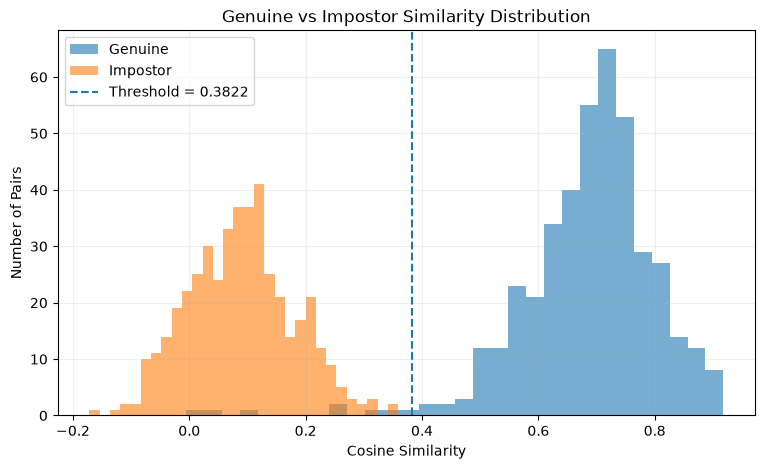

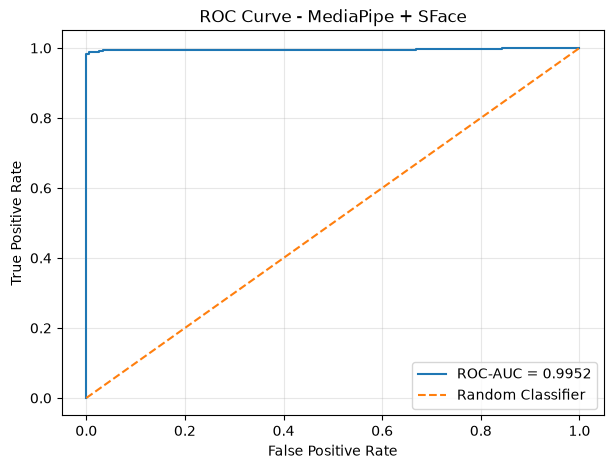

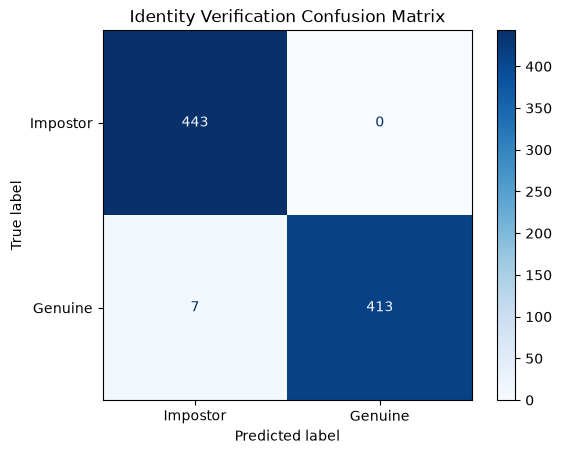

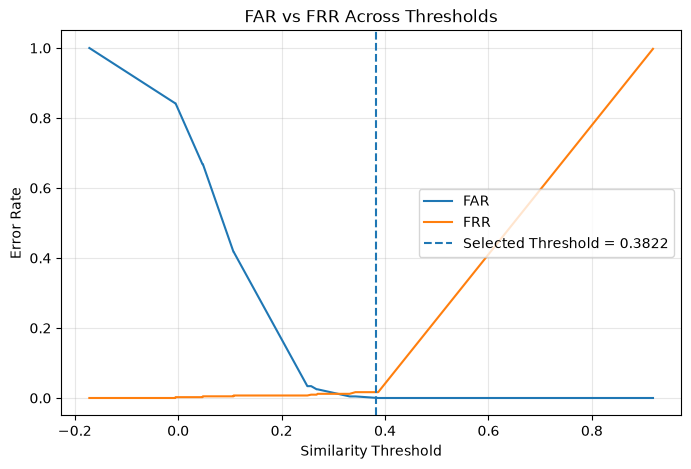

In [27]:
import matplotlib.pyplot as plt
import numpy as np

from sklearn.metrics import (
    roc_curve,
    auc,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 1. Genuine vs Impostor Similarity Distribution

plt.figure(figsize=(9, 5))

plt.hist(
    test_data[test_data["actual_label"] == 1]["similarity"],
    bins=30,
    alpha=0.6,
    label="Genuine"
)

plt.hist(
    test_data[test_data["actual_label"] == 0]["similarity"],
    bins=30,
    alpha=0.6,
    label="Impostor"
)

plt.axvline(
    optimal_threshold,
    linestyle="--",
    label=f"Threshold = {optimal_threshold:.4f}"
)

plt.xlabel("Cosine Similarity")
plt.ylabel("Number of Pairs")
plt.title("Genuine vs Impostor Similarity Distribution")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


# 2. ROC Curve

fpr_values, tpr_values, roc_thresholds = roc_curve(
    y_true, y_scores
)

roc_auc_value = auc(fpr_values, tpr_values)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr_values,
    tpr_values,
    label=f"ROC-AUC = {roc_auc_value:.4f}"
)

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - MediaPipe + SFace")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# 3. Confusion Matrix

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Impostor", "Genuine"]
)

display.plot(cmap="Blues", values_format="d")
plt.title("Identity Verification Confusion Matrix")
plt.show()


# 4. FAR vs FRR Curve

far_values = fpr_values
frr_values = 1 - tpr_values

plt.figure(figsize=(8, 5))

plt.plot(
    roc_thresholds,
    far_values,
    label="FAR"
)

plt.plot(
    roc_thresholds,
    frr_values,
    label="FRR"
)

plt.axvline(
    optimal_threshold,
    linestyle="--",
    label=f"Selected Threshold = {optimal_threshold:.4f}"
)

plt.xlabel("Similarity Threshold")
plt.ylabel("Error Rate")
plt.title("FAR vs FRR Across Thresholds")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

SAVING THE OUTPUTS 

In [28]:
import pickle
from pathlib import Path

# Create output directories
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "lfw_evaluation"
GRAPH_DIR = OUTPUT_DIR / "visualizations"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
GRAPH_DIR.mkdir(parents=True, exist_ok=True)

# 1. Save all evaluation pairs and scores
evaluation_pairs.to_csv(
    OUTPUT_DIR / "evaluation_pairs.csv",
    index=False
)

# 2. Save DevTest predictions
test_data["predicted_label"] = y_pred

test_data.to_csv(
    OUTPUT_DIR / "test_predictions.csv",
    index=False
)

# 3. Save embedding cache
with open(OUTPUT_DIR / "lfw_embedding_cache.pkl", "wb") as file:
    pickle.dump({
        "embedding_cache": embedding_cache,
        "failed_images": failed_images
    }, file)

# 4. Save metrics
metrics = {
    "Threshold": optimal_threshold,
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1 Score": f1,
    "ROC AUC": roc_auc,
    "FAR": far,
    "FRR": frr,
    "True Negatives": int(tn),
    "False Positives": int(fp),
    "False Negatives": int(fn),
    "True Positives": int(tp),
    "Total DevTest Pairs": 1000,
    "Scorable DevTest Pairs": len(test_data),
    "DevTest Coverage": len(test_data) / 1000,
    "Unscorable DevTest Pairs": 1000 - len(test_data)
}

with open(OUTPUT_DIR / "metrics.txt", "w") as file:
    file.write("LFW IDENTITY VERIFICATION EVALUATION\n")
    file.write("=" * 45 + "\n\n")

    for key, value in metrics.items():
        file.write(f"{key}: {value}\n")

print("Evaluation results saved successfully!")
print("Output directory:", OUTPUT_DIR)

Evaluation results saved successfully!
Output directory: D:\Identity_Monitoring\outputs\lfw_evaluation


In [29]:
# Save each graph using its own figure

# Similarity distribution
fig = plt.figure(1)
fig.savefig(GRAPH_DIR / "similarity_distribution.png",
            dpi=300, bbox_inches="tight")

# ROC curve
fig = plt.figure(2)
fig.savefig(GRAPH_DIR / "roc_curve.png",
            dpi=300, bbox_inches="tight")

# Confusion matrix
fig = plt.figure(3)
fig.savefig(GRAPH_DIR / "confusion_matrix.png",
            dpi=300, bbox_inches="tight")

# FAR vs FRR
fig = plt.figure(4)
fig.savefig(GRAPH_DIR / "far_frr_curve.png",
            dpi=300, bbox_inches="tight")

print("All four visualizations saved!")

All four visualizations saved!


<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>